# Step 4 — PPO optimisation on Walker-v0

**Protocol (same for every experiment):** one change at a time vs the baseline (course TD6 hyperparameters), same hand-designed robot, 1M steps, 8 parallel envs, seeds 31, 32, 33.

**Metrics** (the return saturates at ≈ 10.5 once the goal is reached, see notebook 02):
- `train_steps_to_90%_success` — learning efficiency (lower = better),
- `steps_to_goal_last100` / `test_steps_to_goal` — speed of the robot (lower = better),
- `success_last100_%`, `return_last100` — to check nothing breaks.

**Decision rule:** a change is kept only if the gain is larger than the seed-to-seed spread **and** goes the same way on the 3 seeds.

Shared metric code: [`analysis.py`](../analysis.py).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from ppo import load_body
from analysis import experiment_table, load_run

BODY = load_body("walker")
SEEDS = [31, 32, 33]
METRICS = ["return_last100", "success_last100_%", "steps_to_goal_last100", "test_steps_to_goal",
           "train_steps_to_90%_success"]

baseline = experiment_table("walker_baseline", BODY)
summary = {"baseline": baseline[METRICS].agg(["mean", "std"])}


def compare(name, prefix):
    """Per-seed table of an experiment and its mean ± std next to the baseline."""
    table = experiment_table(prefix, BODY)
    summary[name] = table[METRICS].agg(["mean", "std"])
    display(table.round(1))
    side = pd.DataFrame({k: v.loc["mean"].round(1).astype(str) + " ± " + v.loc["std"].round(1).astype(str)
                         for k, v in [("baseline", summary["baseline"]), (name, summary[name])]})
    display(side)
    return table


def plot_vs_baseline(prefix, label, fname):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for run_prefix, color, lab in [("walker_baseline", "tab:gray", "baseline (TD6)"), (prefix, "tab:blue", label)]:
        for i, s in enumerate(SEEDS):
            ep, _ = load_run(Path(f"../runs/{run_prefix}_s{s}"))
            kw = dict(color=color, alpha=0.8, label=lab if i == 0 else None)
            axes[0].plot(ep["end_step"], ep["episode_return"].rolling(50).mean(), **kw)
            axes[1].plot(ep["end_step"], 100 * ep["success"].rolling(50).mean(), **kw)
            succ = ep[ep["success"]]
            axes[2].plot(succ["end_step"], succ["length"].rolling(50).mean(), **kw)
    axes[0].set(title="Return (moving avg 50 ep)", xlabel="Env steps")
    axes[1].set(title="Success rate % (moving avg 50 ep)", xlabel="Env steps", ylim=(0, 105))
    axes[2].set(title="Steps to goal, successful episodes (moving avg 50)", xlabel="Env steps", ylabel="lower = faster")
    axes[0].legend()
    for ax in axes:
        ax.grid(True)
    plt.tight_layout()
    plt.savefig(f"../figures/{fname}", dpi=120)
    plt.show()


print("Baseline (3 seeds):")
display(summary["baseline"].round(1))

/Users/enzo/Desktop/RL/evogym-coevolution/.venv/lib/python3.10/site-packages/evogym/envs/base.py:12: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Using device: cpu


Using device: cpu


Using device: cpu


Baseline (3 seeds):


,return_last100,success_last100_%,steps_to_goal_last100,test_steps_to_goal,train_steps_to_90%_success
mean,10.5,97.3,445.5,404.0,482351.8
std,0.1,2.1,5.6,25.2,38811.6


## 4a — Reward normalisation

**Observation (notebook 02):** Walker rewards are tiny (≈ 0.02 per step) — the opposite of Pendulum, where reward normalisation solved the task (−160 vs −502).
**Hypothesis:** rescaling rewards gives the critic targets of a stable, sensible scale → learning starts earlier.
**Change:** `--norm-reward` (divide each reward by the running std of the discounted return). Nothing else changes.

Using device: cpu


Using device: cpu


Using device: cpu


,return_last100,success_last100_%,steps_to_goal_last100,test_steps_to_goal,test_return,train_steps_to_90%_success
seed,,,,,,
31,10.2,93.0,459.4,439,10.6,396854.3
32,10.5,96.0,464.3,435,10.6,456838.4
33,10.5,90.0,481.0,500,9.5,745685.0


,baseline,4a_norm_reward
return_last100,10.5 ± 0.1,10.4 ± 0.1
success_last100_%,97.3 ± 2.1,93.0 ± 3.0
steps_to_goal_last100,445.5 ± 5.6,468.2 ± 11.3
test_steps_to_goal,404.0 ± 25.2,458.0 ± 36.4
train_steps_to_90%_success,482351.8 ± 38811.6,533125.9 ± 186508.8


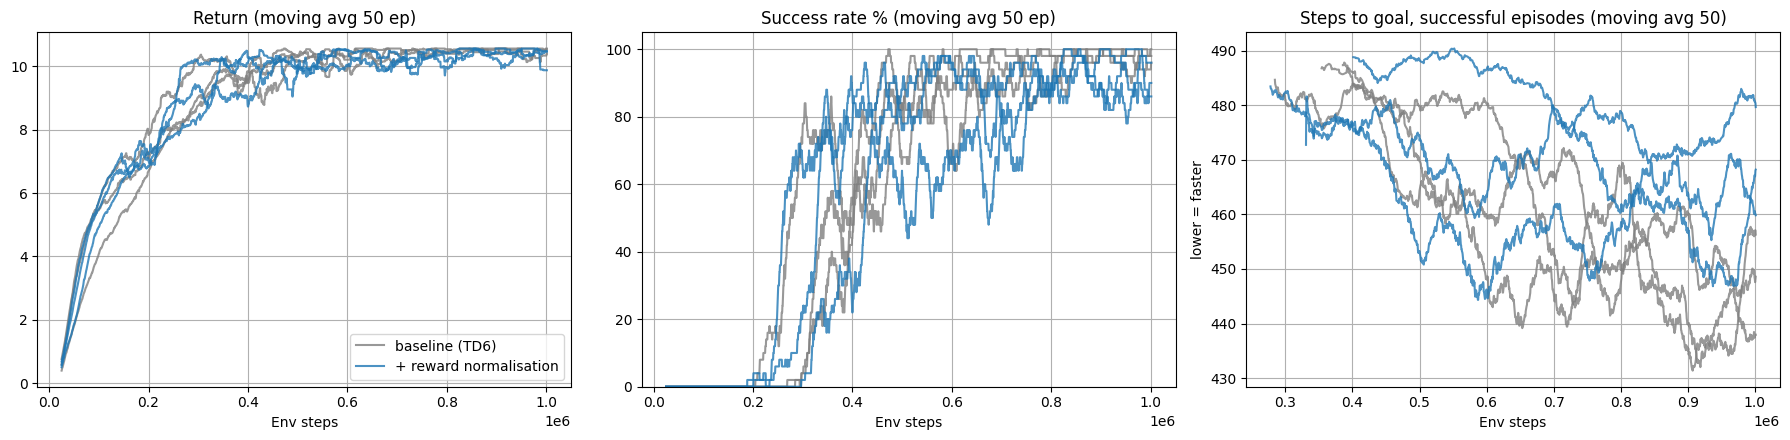

In [2]:
t4a = compare("4a_norm_reward", "walker_4a_normreward")
plot_vs_baseline("walker_4a_normreward", "+ reward normalisation", "04a_norm_reward.png")

### Result 4a — not kept ❌

| Metric | Baseline | + reward normalisation |
|---|---|---|
| Training steps to 90 % success | 482k ± 39k | 533k ± 187k |
| Steps to goal (training, last 100) | 446 ± 6 | 468 ± 11 |
| Steps to goal (deterministic test) | 404 ± 25 | 458 ± 36 (seed 33 does not reach the goal) |
| Success rate (last 100) | 97 ± 2 % | 93 ± 3 % |

- **Slower robot on all 3 seeds** (training steps-to-goal 459 / 464 / 481 vs 439 / 450 / 447) and less reliable.
- **Learning efficiency is not better on average and much less stable:** two seeds reach 90 % success earlier (397k, 457k) but seed 33 needs 746k.
- **Conclusion:** the trick that solved Pendulum does **not** transfer to Walker. Reward normalisation is not kept.

**Why? (hypotheses, not tested):** on Pendulum the problem was returns in the thousands; on Walker the reward is a small displacement whose scale changes as the robot speeds up. Dividing by a running std that keeps growing during training makes the critic's targets drift (non-stationary scale), and the +1 goal bonus is shrunk by the same factor, which may weaken the incentive to finish fast.

## 4b — Observation normalisation

**Observation (notebook 02):** the 74 inputs live on very different scales — centre-of-mass velocity ≈ 1–4, relative voxel positions with a std as low as 0.006. The first layer sees almost constant inputs for most dimensions.
**Hypothesis:** standardising every input ((x − mean) / std, running statistics) lets the network use all of them → faster learning.
**Change:** `--norm-obs`. The statistics live inside the network (buffers saved in `model.pt`), are updated after each PPO update (a rollout and its update see the same normalisation), and the normalised input is clipped to ±10. Nothing else changes.

Using device: cpu


Using device: cpu


Using device: cpu


,return_last100,success_last100_%,steps_to_goal_last100,test_steps_to_goal,test_return,train_steps_to_90%_success
seed,,,,,,
31,9.9,81.0,466.4,461,10.6,323535.0
32,10.3,91.0,455.7,446,10.6,279610.3
33,10.5,97.0,431.0,402,10.6,342148.4


,baseline,4b_norm_obs
return_last100,10.5 ± 0.1,10.2 ± 0.3
success_last100_%,97.3 ± 2.1,89.7 ± 8.1
steps_to_goal_last100,445.5 ± 5.6,451.0 ± 18.2
test_steps_to_goal,404.0 ± 25.2,436.3 ± 30.7
train_steps_to_90%_success,482351.8 ± 38811.6,315097.9 ± 32111.4


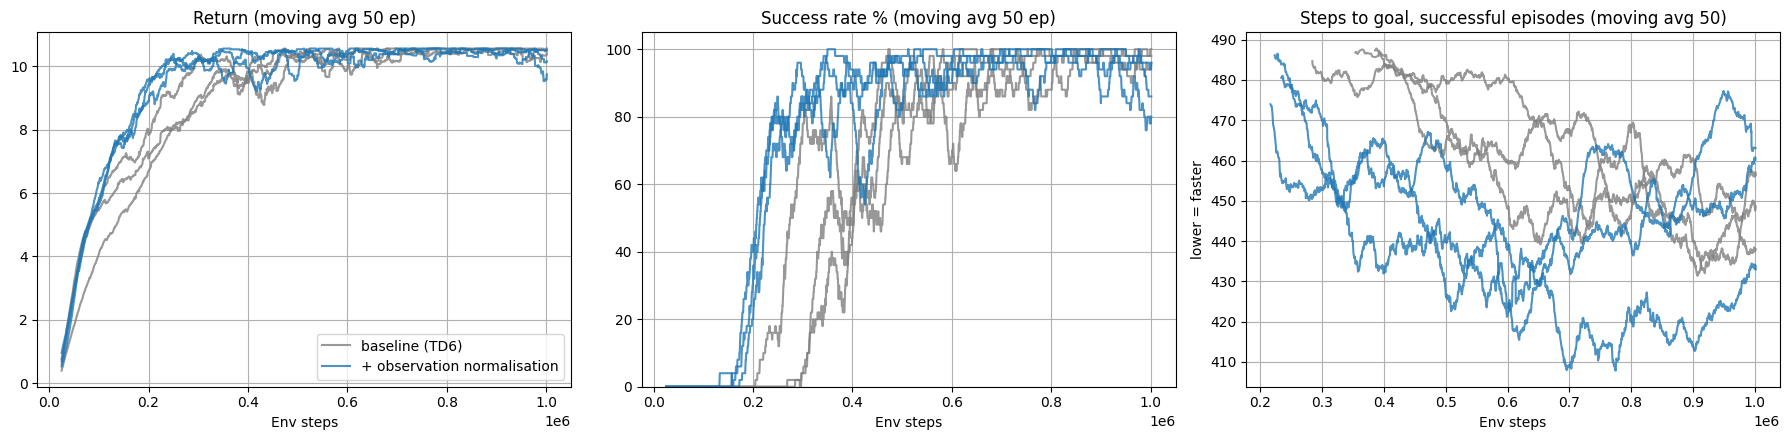

In [3]:
t4b = compare("4b_norm_obs", "walker_4b_normobs")
plot_vs_baseline("walker_4b_normobs", "+ observation normalisation", "04b_norm_obs.png")

### Result 4b — kept ✅ (for learning speed), with a caveat on late stability

| Metric | Baseline | + observation normalisation |
|---|---|---|
| Training steps to 90 % success | 482k ± 39k | **315k ± 32k** |
| Steps to goal (training, last 100) | 446 ± 6 | 451 ± 18 |
| Steps to goal (deterministic test) | 404 ± 25 | 436 ± 31 |
| Success rate (last 100) | 97 ± 2 % | 90 ± 8 % |
| Final policy σ | 0.89 | 0.62 |

- **Learning is ≈ 35 % faster, on all 3 seeds** (324k / 280k / 342k vs 453k / 526k / 468k): the gain (−167k) is much larger than the seed spread (±35k). This passes the decision rule.
- **The final robot is not faster**, and it is less reliable at the end of training: on seeds 31 and 32 the success rate drops in the last ~200 episodes (99 % → 81 % and 99 % → 91 %). The deterministic policy still reaches the goal on all 3 seeds.
- **Conclusion:** observation normalisation is kept — it is the first change that makes PPO learn clearly faster, which is what matters for the evolution (every body gets a short training budget). The late drop has to be checked again in 4e, combined with the other changes.

**Why? (hypotheses, not tested):** faster learning — the inputs that carry the gait information (voxel positions) were ~100× smaller than the velocity; once standardised the network can use them. Late drop — the same ×100 amplification also amplifies tiny position noise, and σ shrinks faster (0.62 vs 0.89), so the policy may over-commit to a gait that is less robust to perturbations.

## 4c — Separate actor and critic

**Observation:** actor and critic share their two hidden layers; the loss is `actor_loss + 0.5 × critic_loss` with one gradient clip on all parameters. The critic may pull the shared features towards what predicts the return (speed, position) rather than what the actor needs (posture, to coordinate 17 muscles).
**Hypothesis:** two independent networks (recommended for continuous control by Andrychowicz et al. 2021, *What Matters in On-Policy RL*) → faster or more stable learning.
**Change:** `--separate-critic` (the critic gets its own 2×128 trunk; without the flag the network is bit-for-bit unchanged). Nothing else changes (no `--norm-obs`: one change at a time).

Using device: cpu


Using device: cpu


Using device: cpu


,return_last100,success_last100_%,steps_to_goal_last100,test_steps_to_goal,test_return,train_steps_to_90%_success
seed,,,,,,
31,10.4,95.0,445.0,414,10.6,494137.7
32,10.5,98.0,465.6,428,10.6,474534.9
33,10.3,92.0,465.9,421,10.6,387852.0


,baseline,4c_separate_critic
return_last100,10.5 ± 0.1,10.4 ± 0.1
success_last100_%,97.3 ± 2.1,95.0 ± 3.0
steps_to_goal_last100,445.5 ± 5.6,458.9 ± 12.0
test_steps_to_goal,404.0 ± 25.2,421.0 ± 7.0
train_steps_to_90%_success,482351.8 ± 38811.6,452174.9 ± 56561.0


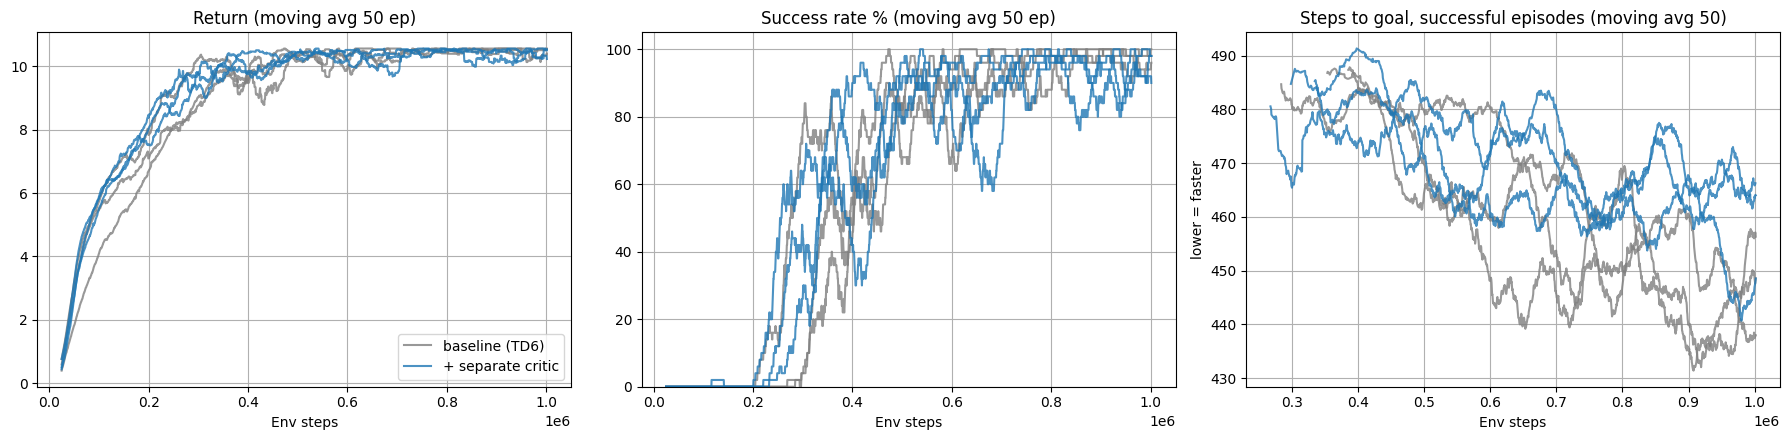

In [4]:
t4c = compare("4c_separate_critic", "walker_4c_sepcritic")
plot_vs_baseline("walker_4c_sepcritic", "+ separate critic", "04c_separate_critic.png")

### Result 4c — not kept ➖ (no clear effect)

| Metric | Baseline | + separate critic |
|---|---|---|
| Training steps to 90 % success | 482k ± 39k | 452k ± 57k |
| Steps to goal (training, last 100) | 446 ± 6 | 459 ± 12 |
| Steps to goal (deterministic test) | 404 ± 25 | 421 ± 7 |
| Success rate (last 100) | 97 ± 2 % | 95 ± 3 % |
| Critic loss (last 20 updates) | 0.024 | 0.019 |

- **Learning speed: no clear gain.** The mean is 30k steps lower, but this is smaller than the seed spread and not the same on every seed (494k / 475k / 388k vs 453k / 526k / 468k). It fails the decision rule.
- **The final robot is slightly slower** (459 vs 446 steps in training) and as reliable as the baseline.
- **The critic fits its targets a bit better** (loss −20 %), but this does not translate into a better policy.
- **Conclusion:** the shared trunk was not the limiting factor on Walker. Separate networks are not kept (simpler network, half the parameters).

**Why? (hypothesis, not tested):** with a small network (2×128) and a value loss weighted 0.5 and already small (≈ 0.02), the critic's gradient does not dominate the shared features, so separating them removes little interference — and the actor loses the features the critic would have helped to learn.

## 4d — Smaller initial exploration (σ₀ = 0.5)

**Observation:** `log_std` starts at 0 (σ = 1, while actions live in [−1, 1]) and is still 0.86–0.96 after 1M steps on the baseline: many sampled actions are clipped to the bounds. The same robot needs 446 steps to reach the goal with noise (training) but 404 without (deterministic test).
**Hypothesis:** starting with σ = 0.5 means less random exploration and less clipping → a cleaner advantage signal → faster learning and a more regular gait.
**Change:** `--log-std-init -0.69` (σ₀ = 0.5; default 0 keeps the baseline). Nothing else changes.

Using device: cpu


Using device: cpu


Using device: cpu


,return_last100,success_last100_%,steps_to_goal_last100,test_steps_to_goal,test_return,train_steps_to_90%_success
seed,,,,,,
31,10.2,71.0,483.1,440,10.6,NaN
32,10.5,95.0,467.9,437,10.6,448365.2
33,10.2,85.0,449.1,392,10.6,424102.1


,baseline,4d_sigma05
return_last100,10.5 ± 0.1,10.3 ± 0.2
success_last100_%,97.3 ± 2.1,83.7 ± 12.1
steps_to_goal_last100,445.5 ± 5.6,466.7 ± 17.0
test_steps_to_goal,404.0 ± 25.2,423.0 ± 26.9
train_steps_to_90%_success,482351.8 ± 38811.6,436233.7 ± 17156.6


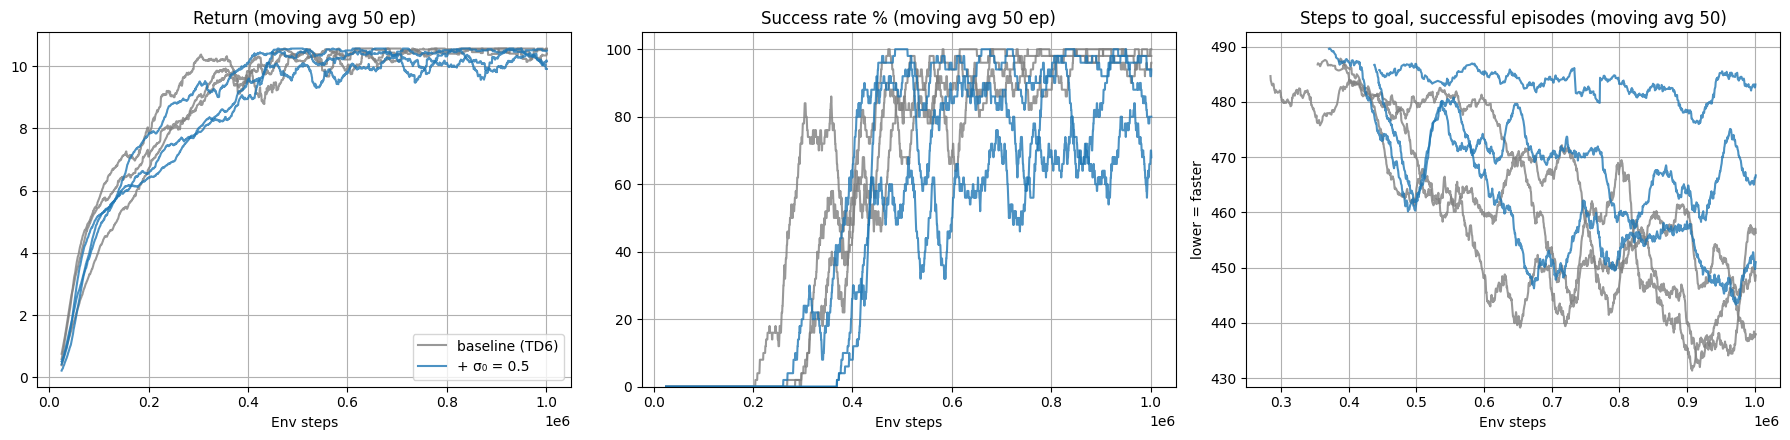

In [5]:
t4d = compare("4d_sigma05", "walker_4d_sigma05")
plot_vs_baseline("walker_4d_sigma05", "+ σ₀ = 0.5", "04d_sigma05.png")

### Result 4d — not kept ❌

| Metric | Baseline | + σ₀ = 0.5 |
|---|---|---|
| Training steps to 90 % success | 482k ± 39k | 448k / 424k, **seed 31 never reaches 90 %** |
| Steps to goal (training, last 100) | 446 ± 6 | 467 ± 17 |
| Steps to goal (deterministic test) | 404 ± 25 | 423 ± 27 |
| Success rate (last 100) | 97 ± 2 % | 84 ± 12 % (71 / 95 / 85) |
| Final policy σ | 0.89 | 0.51 |

- **Less reliable:** seed 31 stays around 60–70 % success for the whole end of training, seed 33 drops to 85 %. (The 436k mean in the table above ignores seed 31, which never reaches 90 %.)
- **Slower robot** on all 3 seeds in training (483 / 468 / 449 vs 439 / 450 / 447).
- **PPO does not want a smaller σ:** σ stays at ≈ 0.5 and even rises on seed 33 (0.57). Starting lower does not help it find a good gait.
- **The train/test gap does not shrink** (467 vs 423, ≈ 44 steps as for the baseline): exploration noise was not the cause of the gap.
- **Conclusion:** σ₀ = 1 is kept. Less exploration makes the robot settle earlier in worse gaits.

**Why? (hypothesis, not tested):** with 17 muscles to coordinate, the walker needs large random variations early on to discover a gait that moves forward; with σ = 0.5 some seeds lock into a mediocre gait (local optimum) and, without an entropy bonus, nothing pushes them out.

## 4e — Summary and PPO config for the evolution (step 5)

Only 4b passed the decision rule, so there is nothing to combine: the final config is the course TD6 hyperparameters + observation normalisation, already measured on 3 seeds in 4b.

Using device: cpu


Using device: cpu


Using device: cpu


Using device: cpu


Using device: cpu


Using device: cpu


... (5 outputs left out)

Using device: cpu


Using device: cpu


Using device: cpu


Using device: cpu


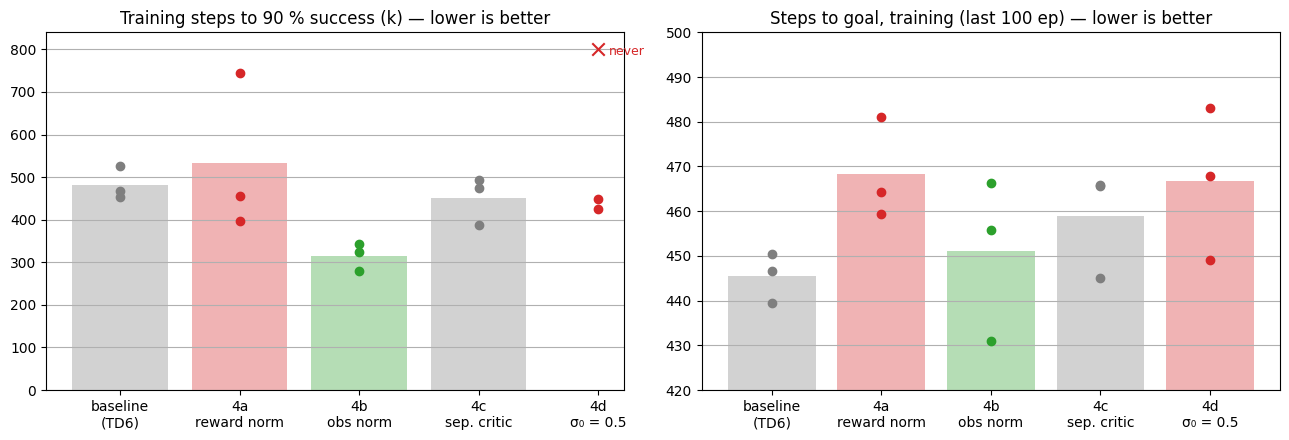

In [6]:
EXPERIMENTS = [("walker_baseline", "baseline\n(TD6)"), ("walker_4a_normreward", "4a\nreward norm"),
               ("walker_4b_normobs", "4b\nobs norm"), ("walker_4c_sepcritic", "4c\nsep. critic"),
               ("walker_4d_sigma05", "4d\nσ₀ = 0.5")]
tables = {p: experiment_table(p, BODY) for p, _ in EXPERIMENTS}
colors = ["tab:gray", "tab:red", "tab:green", "tab:gray", "tab:red"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, title, scale in [(axes[0], "train_steps_to_90%_success", "Training steps to 90 % success (k)", 1e3),
                              (axes[1], "steps_to_goal_last100", "Steps to goal, training (last 100 ep)", 1)]:
    for i, ((p, label), c) in enumerate(zip(EXPERIMENTS, colors)):
        v = tables[p][col] / scale
        never = v.isna()
        if not never.any():  # no mean bar when a seed never reaches 90 % (the mean of the others would mislead)
            ax.bar(i, v.mean(), color=c, alpha=0.35)
        ax.scatter([i] * (~never).sum(), v[~never], color=c, zorder=3)
        if never.any():
            ax.scatter([i] * never.sum(), [800] * never.sum(), marker="x", color=c, s=80, zorder=3)
            ax.annotate("never", (i, 800), textcoords="offset points", xytext=(8, -4), fontsize=9, color=c)
    ax.set_xticks(range(len(EXPERIMENTS)), [l for _, l in EXPERIMENTS])
    ax.set(title=title + " — lower is better")
    ax.grid(True, axis="y")
axes[1].set_ylim(420, 500)
plt.tight_layout()
plt.savefig("../figures/04_summary.png", dpi=120)
plt.show()

| Experiment | Change | Steps to 90 % success | Steps to goal (training) | Verdict |
|---|---|---|---|---|
| Baseline | TD6 hyperparameters | 482k ± 39k | 446 ± 6 | reference |
| 4a | reward normalisation | 533k ± 187k | 468 ± 11 | ❌ worse (yet decisive on Pendulum) |
| 4b | observation normalisation | **315k ± 32k** | 451 ± 18 | ✅ kept: learns ≈ 35 % faster |
| 4c | separate actor and critic | 452k ± 57k | 459 ± 12 | ➖ no clear effect |
| 4d | σ₀ = 0.5 | 1 seed never reaches 90 % | 467 ± 17 | ❌ worse |

**Final config:** [`configs/ppo_best.json`](../configs/ppo_best.json) = TD6 hyperparameters + `norm_obs: true`. For the evolution:
```bash
python evolve.py --env Walker-v0 --ppo-config configs/ppo_best.json ...
```
Checked with a mini evolution run (3 robots × 1 generation): `norm_obs: true` reaches `effective_ppo_kwargs` in `evo_config.json`, and each robot's `model.pt` contains the observation statistics.

**Why it matters for step 5:** each body gets only 500k training steps. With the baseline, the hand-designed robot reaches 90 % success at ≈ 482k steps — right at the limit; with 4b at ≈ 315k. Fewer bodies should be judged bad only because PPO ran out of time, so the fitness should be less noisy.

**Limits:** (1) 4b was measured on the hand-designed robot only — the scale problem (velocity ≫ voxel positions) is the same for every body, but the gain is not verified on evolved bodies; (2) with 4b the success rate drops at the end of training on 2 of 3 seeds (after ≈ 800k steps, beyond the 500k evolution budget); (3) one value per change and 3 seeds: a different value (e.g. σ₀ = 0.8) could behave differently.